In [ ]:
import torch
import matplotlib.pyplot as plt

In [ ]:
temp_at_cel = [15.0 , 30.0 , 45.0 , 60.0 , 75.0 , 90.0 ]
temp_at_vin = [10.0 , 20.0 , 30.0 , 40.0 , 50.0 , 60.0 ]
print('The given temp is' , temp_at_cel)
print("The new scale is" , temp_at_vin)

The given temp is [15.0, 30.0, 45.0, 60.0, 75.0, 90.0]
The new scale is [10.0, 20.0, 30.0, 40.0, 50.0, 60.0]


In [ ]:
temp_at_cel = torch.tensor(temp_at_cel)
temp_at_vin = torch.tensor(temp_at_vin)
print (temp_at_cel)
print(temp_at_vin)

tensor([15., 30., 45., 60., 75., 90.])
tensor([10., 20., 30., 40., 50., 60.])


In [ ]:
def model (temp_at_cel ,w , b):
 return w*temp_at_cel + b

In [ ]:
def loss_fn(temp_pre, temp_at_vin):
 return torch.mean((temp_pre - temp_at_vin)**2)

In [ ]:
w = torch.ones((), requires_grad = True)
b = torch.zeros((), requires_grad = True)
optimizer = torch.optim.SGD([w, b], lr=0.0001) # Significantly reduced learning rate

n_epochs = 500
loss_values = []

for epoch in range(n_epochs):
    temp_pre = model(temp_at_cel, w, b)
    loss = loss_fn(temp_pre, temp_at_vin)

    # Check for NaN loss and break if found
    if torch.isnan(loss):
        print(f"Stopping training: Loss became NaN at epoch {epoch}")
        break

    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    loss_values.append(loss.item())

    if epoch % 100 == 0:
        print(f'Epoch {epoch}: Loss = {loss.item():.4f}')

Epoch 0: Loss = 379.1667
Epoch 100: Loss = 0.0000
Epoch 200: Loss = 0.0000
Epoch 300: Loss = 0.0000
Epoch 400: Loss = 0.0000


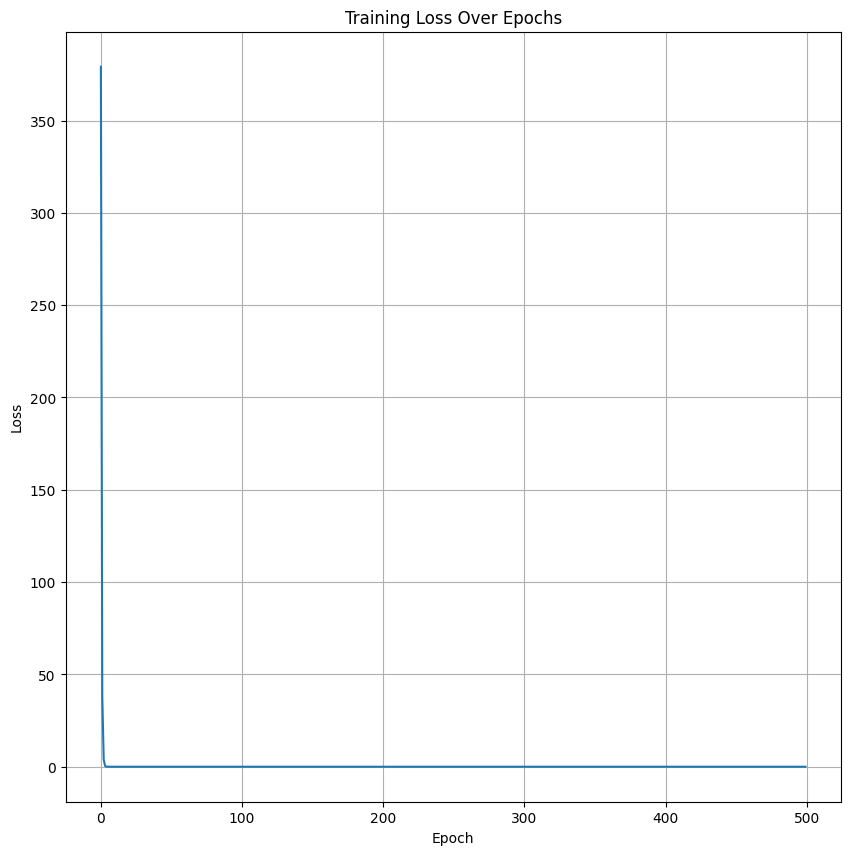

In [ ]:
plt.figure(figsize=(10, 10))
plt.plot(range(n_epochs), loss_values)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Over Epochs')
plt.grid(True)
plt.show()

In [ ]:
print(f'Final learned w: {w.item():.4f}')
print(f'Final learned b: {b.item():.4f}')

final_temp_pre = model(temp_at_cel, w, b)
print('Final predicted temperatures:', final_temp_pre.detach().numpy()) # .detach().numpy() to get plain numbers

Final learned w: 0.6667
Final learned b: -0.0050
Final predicted temperatures: [ 9.996131 19.997292 29.998453 39.99961  50.00077  60.001934]


In [ ]:
print('Please inter the temp in cel')
a = int(input())
temp_in_cel_input = a

# Convert to a PyTorch tensor
temp_in_cel_tensor = torch.tensor(temp_in_cel_input)

# Get the prediction from the trained model
predicted_temp_in_vin = model(temp_in_cel_tensor, w, b)

print(f'Input Temperature (Celsius): {temp_in_cel_input}')
print(f'Predicted Temperature (Vin Scale): {predicted_temp_in_vin.item():.2f}')

Please inter the temp in cel
10
Input Temperature (Celsius): 10
Predicted Temperature (Vin Scale): 6.66
